In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelBinarizer , StandardScaler  ,OneHotEncoder
from sklearn.metrics import (
    r2_score,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error,
    mean_squared_error,
)

In [2]:
data = pd.read_csv('mushrooms.csv')

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [4]:
data.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [5]:
data.nunique()

class                        2
cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   5
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64

In [6]:
#? this will be used for OneHotEncoder(drop='if_binary')
two_class_cols = data.columns[data.nunique() == 2].drop('class')
two_class_cols


Index(['bruises', 'gill-attachment', 'gill-spacing', 'gill-size',
       'stalk-shape'],
      dtype='object')

***By adding drop='if_binary', you force OneHotEncoder to drop the redundant column. It collapses the category into exactly one column (0 or 1), which keeps the KNN distance math perfectly balanced.***


In [7]:
#? this will be used for OneHotEncoder(sparse_output=False , handle_unknown='ignore') 
rest_of_cols = [col for col in data.columns if col not in two_class_cols]
rest_of_cols.remove('class')
rest_of_cols

['cap-shape',
 'cap-surface',
 'cap-color',
 'odor',
 'gill-color',
 'stalk-root',
 'stalk-surface-above-ring',
 'stalk-surface-below-ring',
 'stalk-color-above-ring',
 'stalk-color-below-ring',
 'veil-type',
 'veil-color',
 'ring-number',
 'ring-type',
 'spore-print-color',
 'population',
 'habitat']

***Sparse Matrix (sparse_output=True): By default, scikit-learn compresses this data into a special "Sparse Matrix" memory format. Instead of saving all the zeros, it only remembers the coordinates of where the 1s are. This saves RAM.***

***Why you need sparse_output=False here:***

***Compatibility: Many transformers (like StandardScaler) and algorithms cannot read a sparse matrix format directly; they expect standard numeric arrays.***

***Debugging: It allows you to instantly print your encoded data, look at it, or convert it back into a visible Pandas DataFrame.***

In [8]:
data.isna().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
x = data.drop('class' , axis = 1)
y = data['class']
y = y.map({'p' : 1 , 'e' : 0})
y= np.reshape(y , (y.shape[0] ,1 ))
x_train , x_test , y_train , y_test = train_test_split(x ,y , test_size=0.2 , random_state=42)

In [11]:
preprocessing = ColumnTransformer(
    transformers=[
        ("two_class" , OneHotEncoder(drop='if_binary') , two_class_cols  ),
        ("rest_features" , OneHotEncoder(sparse_output=False , handle_unknown='ignore') , rest_of_cols ),
    ]
)

In [12]:
K_Ranges = list(range(2,151))
Lr_ranges = np.arange(0.001,1.001,0.001).tolist()
Iter_ranges = list(range(1000,100001))
f1_Knn_train = []
f1_Knn_test = []
f1_Log_reg_lr_train = []
f1_Log_reg_lr_test = []
f1_Log_reg_iter_train = []
f1_Log_reg_iter_test = []

In [13]:
#! the once time pipeline :
pipe = Pipeline(
    steps=[
        ("Data_clean" , preprocessing),
    ]
)
x_train = pipe.fit_transform(x_train)
x_test = pipe.transform(x_test)

## KNN

In [14]:
for i in K_Ranges:
    Knn = KNeighborsClassifier(n_neighbors=i)
    Knn.fit(x_train,y_train.ravel())
    pred_train = Knn.predict(x_train)
    pred_test = Knn.predict(x_test)
    f1_Knn_train.append(f1_score(y_train.ravel(),pred_train))
    f1_Knn_test.append(f1_score(y_test.ravel(),pred_test))
    

***The .ravel() function squashes that matrix down into a simple, single-line sequence of values, which perfectly matches what KNeighborsClassifier expects.***

## logistice_regression

In [15]:
from classification import logistic_regression # self made one to tune the Learning rate !
for i in Lr_ranges:
    log_reg = logistic_regression(100 , i) # 100 is the default number of iterations 
    log_reg.fit(x_train,y_train)
    pred_train = log_reg.predict(x_train)
    pred_test = log_reg.predict(x_test)
    f1_Log_reg_lr_train.append(f1_score(y_train,pred_train))
    f1_Log_reg_lr_test.append(f1_score(y_test,pred_test))
    

In [16]:
for i in Iter_ranges:
    real_model = LogisticRegression(max_iter= i)
    real_model.fit(x_train,y_train.ravel())
    pred_train = real_model.predict(x_train)
    pred_test = real_model.predict(x_test)
    f1_Log_reg_iter_train.append(f1_score(y_train.ravel(),pred_train))
    f1_Log_reg_iter_test.append(f1_score(y_test.ravel(),pred_test))
    

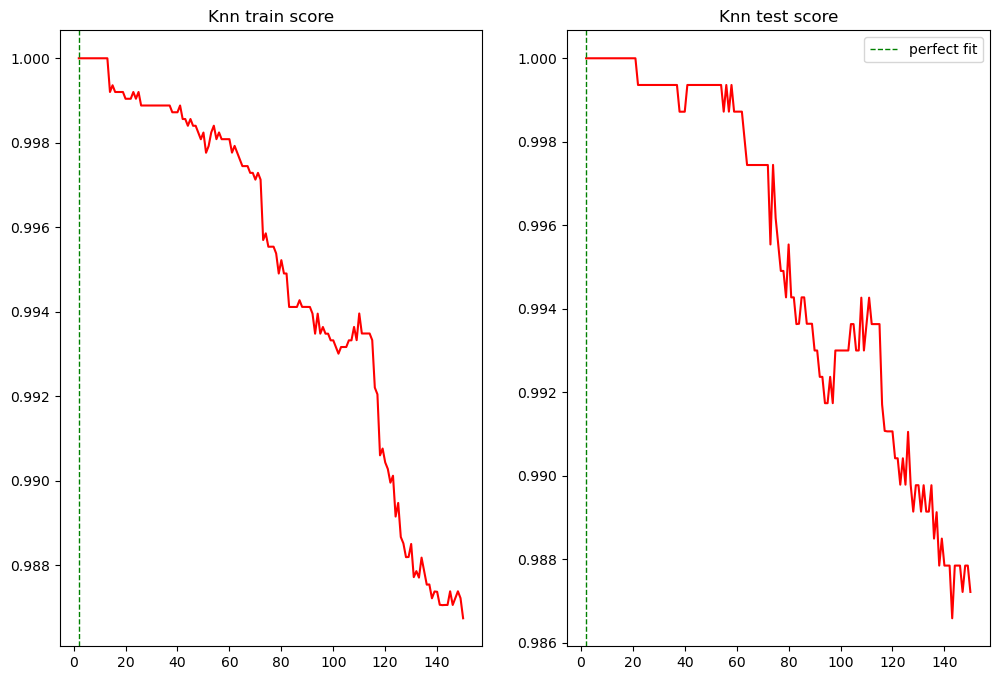

In [18]:
best_k = K_Ranges[np.argmax(f1_Knn_test)]
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
sns.lineplot(x = K_Ranges , y = f1_Knn_train , c = "red" ,ax= ax[0])
sns.lineplot(x = K_Ranges , y = f1_Knn_test , c = "red" , ax = ax[1])
ax[0].axvline(x = best_k,  c  ='g' , linestyle = '--' , linewidth = 1 ,   label = 'perfect fit'  )
ax[1].axvline(x = best_k,  c  ='g' , linestyle = '--' , linewidth = 1 ,   label = 'perfect fit'  )
ax[0].set_title("Knn train score")
ax[1].set_title("Knn test score")
plt.legend()
plt.show()

***for complex model : K is too large. The model is just averaging everything together and losing its predictive power.What it looks like: Both the Training line and the Test line slope downward together into low scores(underfitting)***

***The Training line has a near-perfect F1-score (1.0), but the Test line is significantly lower.what it looks like: the training line slope is high while the test line is is getting downward(overfitting)***

***Sweet Spot (Peak of the Test line): when the test line and the train line slopes goes up near 1.0 (perfect fit )***

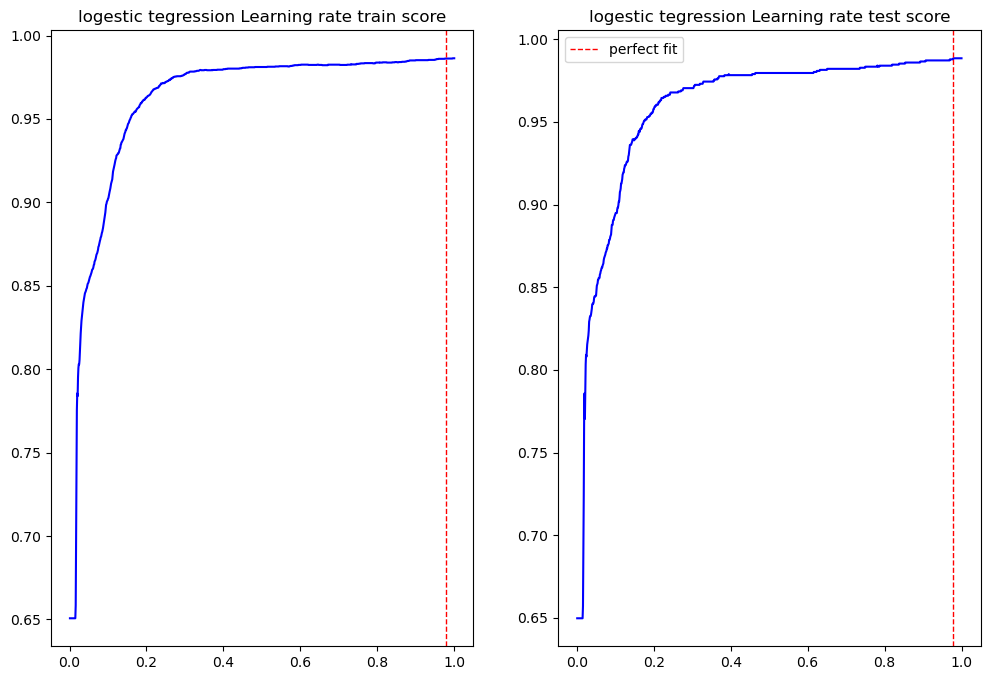

In [19]:
best_lr = Lr_ranges[np.argmax(f1_Log_reg_lr_test)]
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
sns.lineplot(x = Lr_ranges , y = f1_Log_reg_lr_train , c = "blue", ax = ax[0])
sns.lineplot(x = Lr_ranges , y = f1_Log_reg_lr_test , c = "blue",  ax = ax[1])
ax[0].axvline(x = best_lr ,  c  ='r' , linestyle = '--' , linewidth = 1 ,   label = 'perfect fit'  )
ax[1].axvline(x = best_lr ,  c  ='r' , linestyle = '--' , linewidth = 1 ,   label = 'perfect fit'  )
ax[0].set_title("logestic tegression Learning rate train score")
ax[1].set_title("logestic tegression Learning rate test score")
plt.legend()
plt.show()

***low learning rate make the model converge slowly but accurately , while higher learning rate may make the model overshoots !***

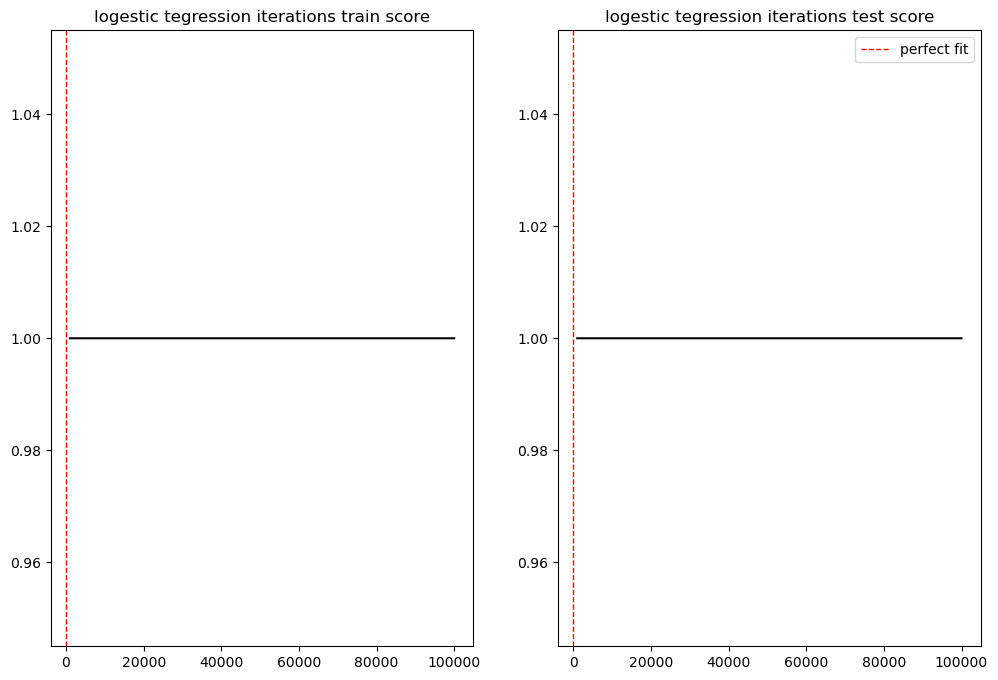

In [20]:
best_iter = K_Ranges[np.argmax(f1_Log_reg_iter_test)]

fig, ax = plt.subplots(1, 2, figsize=(12, 8))
sns.lineplot(x = Iter_ranges , y = f1_Log_reg_iter_train , c = "black" ,  ax = ax[0])
sns.lineplot(x = Iter_ranges , y = f1_Log_reg_iter_test , c = "black" ,  ax = ax[1])
ax[0].axvline(x = best_iter ,  c  ='r' , linestyle = '--' , linewidth = 1 ,   label = 'perfect fit'  )
ax[1].axvline(x = best_iter ,  c  ='r' , linestyle = '--' , linewidth = 1 ,   label = 'perfect fit'  )
ax[0].set_title("logestic tegression iterations train score")
ax[1].set_title("logestic tegression iterations test score")
plt.legend()
plt.show()

***the model the max_iter the model the model is likely to converge but it will reach a point that more iterations adds no benift!***